In [10]:
%pip install --user folium
%pip install --user ipywidgets




Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [24]:
from IPython.display import display, HTML

# Cette commande force les zones de sortie à s'adapter à 100% de leur contenu
display(HTML("<style>.output_scroll { height: auto !important; max-height: none !important; }</style>"))


In [12]:
import ipywidgets as wdg
from ipywidgets import interact 

In [6]:
import pandas as pd
import numpy as np
import folium
import branca.colormap as cm
import matplotlib.pyplot as plt

history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")
stations_toulouse = pd.read_parquet("stations_toulouse.parquet")


In [7]:
#ajout colonne horaire dans history_toulouse_train
index_heure= (
    history_toulouse_train
    .index
    .get_level_values("commit_at")
)

heure = index_heure.hour.astype(str).str.zfill(2)
minute = index_heure.minute.astype(str).str.zfill(2)

history_toulouse_train["horaire"] = heure + ":" + minute

print(history_toulouse_train)


                                              bikes  stands horaire
station                  commit_at                                 
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9   12:15
                         2023-08-05 12:30:00     10       9   12:30
                         2023-08-05 12:45:00     10       9   12:45
                         2023-08-05 13:00:00     11       8   13:00
                         2023-08-05 13:15:00     11       8   13:15
...                                             ...     ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3   15:00
                         2026-02-12 15:15:00      0       3   15:15
                         2026-02-12 15:30:00      0       3   15:30
                         2026-02-12 15:45:00      0       3   15:45
                         2026-02-12 16:00:00      0       3   16:00

[40012622 rows x 3 columns]


In [33]:
#normalisation du nombres de velos selon un taux de remplsissage
history_toulouse_train["taux_remplissage"] = (
    history_toulouse_train["bikes"]/( history_toulouse_train["bikes"] +  history_toulouse_train["stands"])*100
)
history_toulouse_train["taux_remplissage"]= history_toulouse_train["taux_remplissage"].round(1)

print(history_toulouse_train)

                                              bikes  stands horaire  \
station                  commit_at                                    
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9   12:15   
                         2023-08-05 12:30:00     10       9   12:30   
                         2023-08-05 12:45:00     10       9   12:45   
                         2023-08-05 13:00:00     11       8   13:00   
                         2023-08-05 13:15:00     11       8   13:15   
...                                             ...     ...     ...   
TEST BEE                 2026-02-12 15:00:00      0       3   15:00   
                         2026-02-12 15:15:00      0       3   15:15   
                         2026-02-12 15:30:00      0       3   15:30   
                         2026-02-12 15:45:00      0       3   15:45   
                         2026-02-12 16:00:00      0       3   16:00   

                                              taux_remplissage  
station    

In [10]:
history_toulouse_train.dtypes

bikes      uint8
stands     uint8
horaire      str
dtype: object

In [111]:
def map_station_by_hour(heure):

    date_stations=history_toulouse_train[history_toulouse_train["horaire"]==heure]
    
    max_by_stations=(
        date_stations
        .groupby(level=["station"])
        ["taux_remplissage"].mean()
        .round(1)
        .copy()
    )

    
    stations_toulouse["taux_remplissage"]=(
        stations_toulouse["station"].map(max_by_stations)
    )

        

    
        # Carte centrée sur les stations
    m = folium.Map(
        location=[
            stations_toulouse["latitude"].mean(),
            stations_toulouse["longitude"].mean()
        ],
        zoom_start=12
    )


    # Échelle de couleurs basée sur le nombre maximum de vélos
    colormap = cm.LinearColormap(
        colors=["blue", "cyan", "yellow", "orange", "red"],
        vmin=stations_toulouse["taux_remplissage"].min(),
        vmax=stations_toulouse["taux_remplissage"].max(),
        caption="Taux de remplissage de la station"
    )


    # Ajouter les stations
    for _, row in stations_toulouse.dropna(
        subset=["taux_remplissage"]
    ).iterrows():
    
        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=6,
            color=colormap(row["taux_remplissage"]),
            fill=True,
            fill_color=colormap(row["taux_remplissage"]),
            fill_opacity=0.8,
            popup=folium.Popup(
                f"""
                <b>Station :</b> {row['station']}<br>
                <b>ID :</b> {row['station_id']}<br>
                <b>Taux de remplissage :</b>
                {row['taux_remplissage']}
                """,
                max_width=300
            ),
            tooltip=(
                f"{row['station']} : "
                f"{row['taux_remplissage']}% remplie"
            )
        ).add_to(m)
    
    # Ajouter la légende
    colormap.add_to(m)
    
    return m
        

In [112]:
liste_heures = sorted(history_toulouse_train["horaire"].unique())

curseur = wdg.SelectionSlider(
    options = liste_heures,
    value = "08:30",
    description = "horaire :",
    continuous_update = False,
    layout = wdg.Layout(width = "500px")
)

interact(map_station_by_hour, heure = curseur)

interactive(children=(SelectionSlider(continuous_update=False, description='horaire :', index=34, layout=Layou…

<function __main__.map_station_by_hour(heure)>

**courbes d'evoulution de la moyenne selon des groupes par repartion geographique**


In [98]:
#centre de la carte 

lat_centre = stations_toulouse["latitude"].median()
lon_centre = stations_toulouse["longitude"].median()
print(lat_centre, lon_centre)
#capitole de toulouse
"""lat_centre = 43.604429
lon_centre = 1.443812"""


# formule de calcul des distance
def distance_by_center(lat_c, lon_c, lat, lon):
    #conversion en randians
    lat_c, lon_c, lat, lon = map(np.radians,[lat_c,lon_c,lat,lon])

    #formule proximité plane(pythagore)

    dlat = lat_c -lat
    dlon = (lon_c - lon)*np.cos((lat_c+lat)/2)

    distance = 6371*np.sqrt(dlat**2+dlon**2)

    return distance
    


43.601607 1.44293


In [124]:
#creation des groupes
stations_toulouse["distance_centre"] = distance_by_center(
    lat_centre, lon_centre, stations_toulouse["latitude"], stations_toulouse["longitude"]
)

stations_toulouse["groupe"] = pd.qcut(
    stations_toulouse["distance_centre"], q=3, labels=["centre", "milieu", "exterieur"]
)

a,b,c = stations_toulouse.groupby("groupe")["distance_centre"].median()

print(a,b,c)
print(stations_toulouse)

1.0986563349012683 2.8996563401374633 5.5581228805344765
                               station  longitude   latitude  station_id  \
0             00001 - POIDS DE L'HUILE   1.445475  43.604190           0   
1                    00002 - LAFAYETTE   1.445306  43.604885           1   
2    00003 - ALSACE - LORRAINE - POMME   1.445454  43.603302           2   
3      00003 - ALSACE-LORRAINE - POMME   1.445454  43.603302           3   
4                        00003 - POMME   1.445454  43.603302           4   
..                                 ...        ...        ...         ...   
858            TOLOSANE - PASTOURELLES   1.477417  43.543115         858   
859               TOLOSANE - POUCIQUOT   1.469875  43.551101         859   
860               TOURNEFEUILLE MAIRIE   1.346042  43.583665         860   
861                VELASQUEZ - TAMARIS   1.390347  43.621004         861   
862                        ZOLA - DALÍ   1.371961  43.644069         862   

     nombre_max_de_velos  nomb

**carte afficant les stations par groupes :**


In [127]:

# Carte centrée sur les stations
m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

#creation de la legende
palette = {
    "centre": {"couleur": "red", "label" : "centre" },
    "milieu": {"couleur": "yellow", "label" : "milieu" },
    "exterieur": {"couleur": "blue", "label" : "exterieur" }

}




# Ajouter les stations


for nom_groupe, config in palette.items():
    #legende triable
    fg = folium.FeatureGroup(name=config["label"])

    stations_groupe = stations_toulouse[stations_toulouse["groupe"]==nom_groupe]
    for _, row in stations_groupe.dropna(
        subset=["taux_remplissage"]
    ).iterrows():
        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=6,
            color= config["couleur"],
            fill=True,
            fill_color= config["couleur"],
            fill_opacity=0.8,
            popup=folium.Popup(
                f"""
                <b>Station :</b> {row['station']}<br>
                <b>ID :</b> {row['station_id']}<br>
                <b>Taux de remplissage :</b>
                {row['taux_remplissage']}
                """,
                max_width=300
            ),
            tooltip=(
                f"{row['station']} : "
                f"{row['taux_remplissage']}% remplie"
            )
        ).add_to(fg)
    fg.add_to(m)
        
# Ajouter la légende
folium.LayerControl(collapsed=False).add_to(m)
m

In [100]:
history_toulouse_train["groupe"] = (
    history_toulouse_train
        .index.get_level_values("station")
        .map(stations_toulouse
            .set_index("station")["groupe"]
            )
)
print(history_toulouse_train)

                                              bikes  stands horaire  \
station                  commit_at                                    
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9   12:15   
                         2023-08-05 12:30:00     10       9   12:30   
                         2023-08-05 12:45:00     10       9   12:45   
                         2023-08-05 13:00:00     11       8   13:00   
                         2023-08-05 13:15:00     11       8   13:15   
...                                             ...     ...     ...   
TEST BEE                 2026-02-12 15:00:00      0       3   15:00   
                         2026-02-12 15:15:00      0       3   15:15   
                         2026-02-12 15:30:00      0       3   15:30   
                         2026-02-12 15:45:00      0       3   15:45   
                         2026-02-12 16:00:00      0       3   16:00   

                                              taux_remplissage     groupe  


In [ ]:
#calcul des quartile de chaque groupe 

stat = (
    history_toulouse_train.groupby(["horaire","groupe"])["taux_remplissage"]
    .agg(
        moyenne="mean",
        mediane="median",
        q1= lambda x: x.quantile(0.25),
        q3= lambda x: x.quantile(0.75)
    )
    #.quantile([0.25,0.5,0.75],"higher")
    #.unstack()
)

stat.columns = ["q1","mediane","q3"]
print(stat)

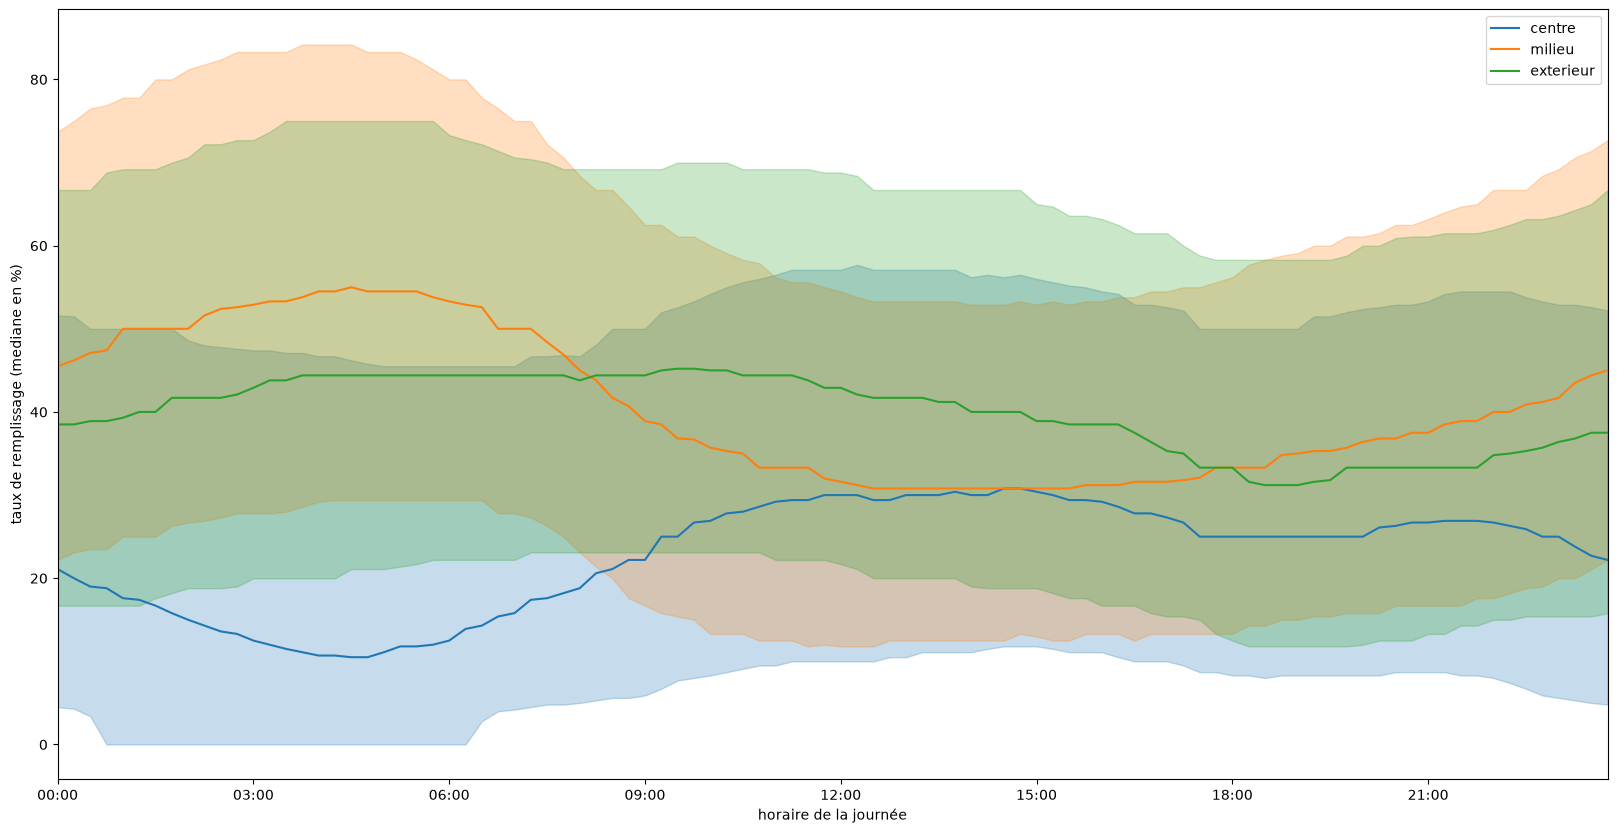

In [128]:
#creation de l'axe des abscisses
plage_horaire = stat.index.get_level_values("horaire").unique()
x = np.arange(len(plage_horaire))

#tracage des courbes

fig, ax = plt.subplots(figsize = (20, 10))

for nom in stat.index.get_level_values("groupe").unique():
    s = stat.xs(nom, level = "groupe").reindex(plage_horaire)
    (ligne,) = ax.plot(x, s["mediane"], label = nom)
    ax.fill_between(x, s["q1"], s["q3"], color = ligne.get_color(), alpha=0.25)

ax.set_xticks(x[::12])
ax.set_xticklabels(plage_horaire[::12])
ax.set_xlim(0, len(plage_horaire) -1)
ax.set_xlabel("horaire de la journée")
ax.set_ylabel("taux de remplissage (mediane en %)")
ax.legend()
plt.savefig("relation_geographique_med.svg", format="svg", bbox_inches="tight")
plt.show()

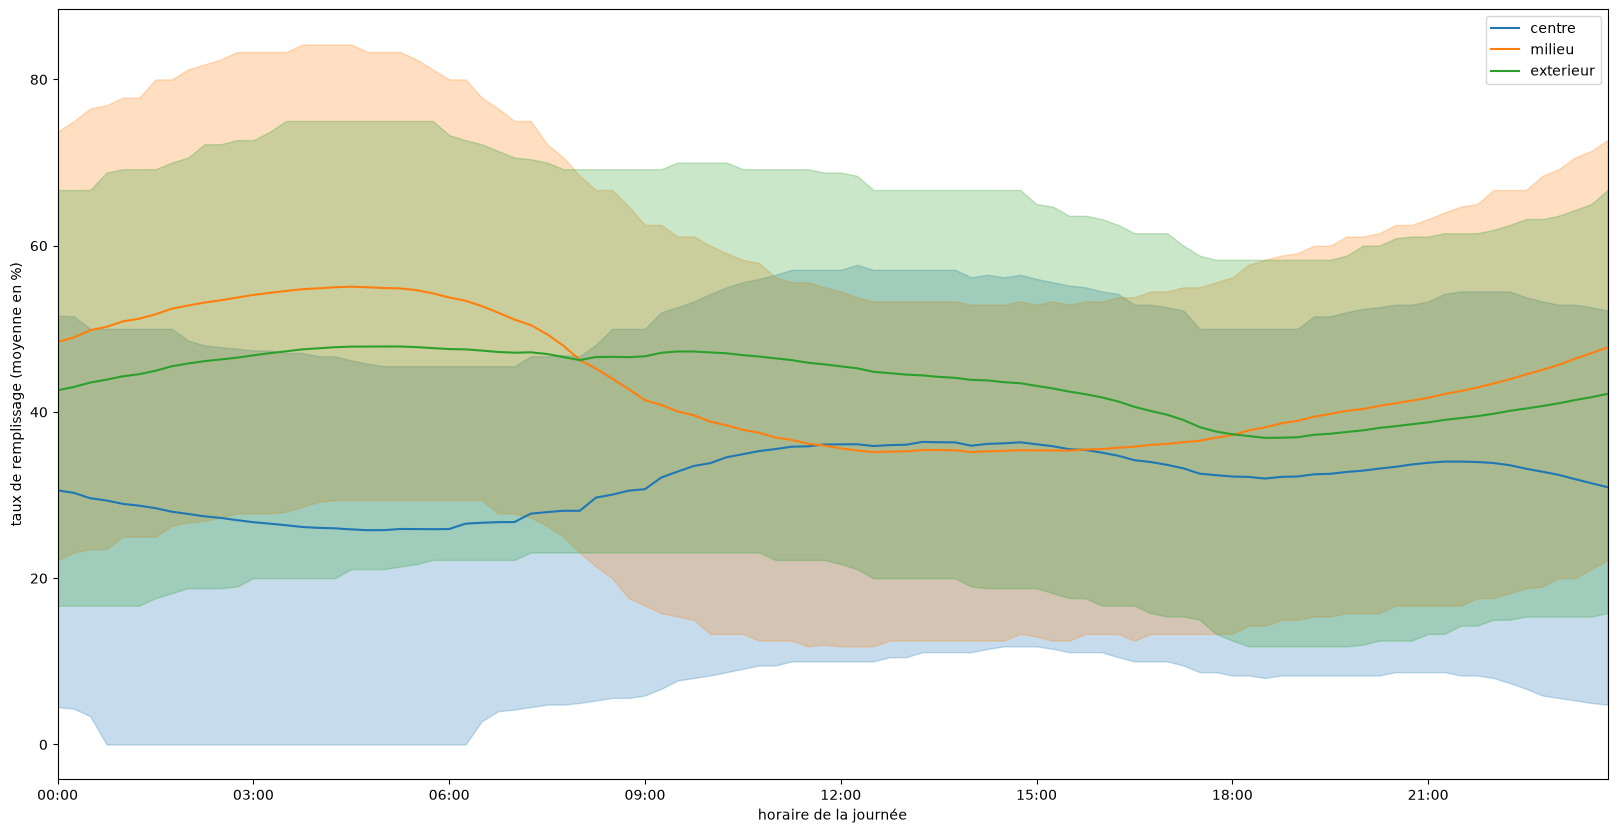

In [129]:
#tracage des courbes

fig, ax = plt.subplots(figsize = (20, 10))

for nom in stat.index.get_level_values("groupe").unique():
    s = stat.xs(nom, level = "groupe").reindex(plage_horaire)
    (ligne,) = ax.plot(x, s["moyenne"], label = nom)
    ax.fill_between(x, s["q1"], s["q3"], color = ligne.get_color(), alpha=0.25)

ax.set_xticks(x[::12])
ax.set_xticklabels(plage_horaire[::12])
ax.set_xlim(0, len(plage_horaire) -1)
ax.set_xlabel("horaire de la journée")
ax.set_ylabel("taux de remplissage (moyenne en %)")
ax.legend()
plt.savefig("relation_geographique_mean.svg", format="svg", bbox_inches="tight")
plt.show()